# Fine tune MAE-DFER on ElderReact dataset

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!git clone https://github.com/sunlicai/MAE-DFER.git
%cd MAE-DFER
!pip install timm==0.4.12 einops decord tensorboardX opencv-python scikit-learn

Mounted at /content/drive
Cloning into 'MAE-DFER'...
remote: Enumerating objects: 259, done.
remote: Counting objects: 100% (78/78), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 259 (delta 50), reused 17 (delta 17), pack-reused 181 (from 1)
Receiving objects: 100% (259/259), 16.52 MiB | 20.58 MiB/s, done.
Resolving deltas: 100% (98/98), done.
/content/MAE-DFER
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 154.5 MB/s  0:00:00
  Attempting uninstall: timm
    Found existing installation: timm 1.0.31
    Uninstalling timm-1.0.31:
      Successfully uninstalled timm-1.0.31
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [timm]


In [ ]:
# @title
# Fine-tune MAE-DFER (pre-trained checkpoint-49) on ElderReact (multi-label, 6 emotions)
#
# Colab usage:
#   from google.colab import drive; drive.mount('/content/drive')
#   !git clone https://github.com/sunlicai/MAE-DFER.git /content/MAE-DFER
#   !pip install timm==0.4.12 einops decord tensorboardX opencv-python scikit-learn
#   !python finetune_elderreact.py

import os, sys, random, time, glob
import numpy as np
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from decord import VideoReader, cpu
from sklearn.metrics import f1_score, average_precision_score

# ============================ CONFIG ============================
REPO_DIR   = '/content/MAE-DFER'
CKPT       = '/content/drive/MyDrive/plugg/year5/projektkurs/checkpoints/checkpoint-49.pth'     # <-- edit
DATA_DIR   = '/content/drive/MyDrive/plugg/year5/projektkurs/ElderReact_Data'               # <-- edit (folder with videos)
LABEL_FILE = '/content/drive/MyDrive/plugg/year5/projektkurs/ElderReact_Data/train_labels.txt'    # <-- edit (name, 6 binary cols)
OUT_DIR    = '/content/drive/MyDrive/plugg/year5/projektkurs/elderreact_ft'

MODEL_NAME = 'vit_base_dim512_no_depth_patch16_160'  # check against the repo's DFEW fine-tune script
EMOTIONS   = ['anger', 'disgust', 'fear', 'happiness', 'sadness', 'surprise']  # set to match your column order
NUM_FRAMES, TUBELET, SIZE = 16, 2, 160

EPOCHS, BATCH_SIZE = 30, 8
LR_BACKBONE, LR_HEAD, WEIGHT_DECAY = 5e-5, 5e-4, 0.05
WARMUP_EPOCHS = 3
VAL_FRACTION, SEED = 0.2, 42     # random split (swap for the official ElderReact split when you have it)
MAX_VIDEOS = 10                # e.g. 200 to start tiny
USE_FACE_CROP = True             # Haar-cascade face crop (fast, rough); False = full frame
NUM_WORKERS = 2
# =================================================================

sys.path.append(REPO_DIR)
import modeling_finetune  # noqa: F401  (registers models with timm)
from timm.models import create_model

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
os.makedirs(OUT_DIR, exist_ok=True)

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
VIDEO_EXTS = ['', '.mp4', '.avi', '.mov', '.mkv', '.webm']


# ------------------------- labels / data -------------------------
def find_video(name):
    for ext in VIDEO_EXTS:
        p = os.path.join(DATA_DIR, name + ext)
        if os.path.isfile(p):
            return p
    hits = glob.glob(os.path.join(DATA_DIR, '**', os.path.splitext(name)[0] + '.*'), recursive=True)
    return hits[0] if hits else None


def read_labels(path):
    items, missing = [], 0
    with open(path) as f:
        for line in f:
            parts = line.replace(',', ' ').split()
            if len(parts) < 7:
                continue
            try:
                y = [float(v) for v in parts[1:7]]
            except ValueError:      # header line
                continue
            vp = find_video(parts[0])
            if vp is None:
                missing += 1
                continue
            items.append((vp, y))
    print(f'Found {len(items)} labelled videos ({missing} listed in txt but not on disk)')
    return items


# _face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
USE_FACE_CROP = False

def face_box(frame, margin=0.3):
    gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
    faces = _face_cascade.detectMultiScale(gray, 1.1, 5, minSize=(40, 40))
    if len(faces) == 0:
        return None
    x, y, w, h = max(faces, key=lambda b: b[2] * b[3])
    H, W = frame.shape[:2]
    s = int(max(w, h) * (1 + margin)); cx, cy = x + w // 2, y + h // 2
    x0, y0 = max(0, cx - s // 2), max(0, cy - s // 2)
    return x0, y0, min(W, x0 + s), min(H, y0 + s)


class ElderReactDataset(Dataset):
    def __init__(self, items, train):
        self.items, self.train = items, train

    def __len__(self):
        return len(self.items)

    def _indices(self, n):
        seg = np.linspace(0, n, NUM_FRAMES + 1)
        if self.train:   # random frame inside each segment
            idx = [random.randint(int(seg[i]), max(int(seg[i]), int(seg[i + 1]) - 1)) for i in range(NUM_FRAMES)]
        else:            # centre of each segment
            idx = [int((seg[i] + seg[i + 1]) / 2) for i in range(NUM_FRAMES)]
        return np.clip(idx, 0, n - 1)

    def __getitem__(self, i):
        path, y = self.items[i]
        try:
            vr = VideoReader(path, ctx=cpu(0))
            frames = vr.get_batch(self._indices(len(vr))).asnumpy()          # T,H,W,3
        except Exception as e:
            print('bad video', path, e)
            frames = np.zeros((NUM_FRAMES, SIZE, SIZE, 3), dtype=np.uint8)

        if USE_FACE_CROP:
            box = face_box(frames[len(frames) // 2])
            if box:
                x0, y0, x1, y1 = box
                frames = frames[:, y0:y1, x0:x1]

        flip = self.train and random.random() < 0.5
        out = []
        for f in frames:
            f = cv2.resize(f, (SIZE, SIZE))
            if flip:
                f = f[:, ::-1]
            out.append((f.astype(np.float32) / 255.0 - MEAN) / STD)
        x = torch.from_numpy(np.stack(out).transpose(3, 0, 1, 2).copy())    # C,T,H,W
        return x, torch.tensor(y, dtype=torch.float32)


# ------------------------- model -------------------------
def build_model():
    model = create_model(MODEL_NAME, pretrained=False, num_classes=len(EMOTIONS),
                         all_frames=NUM_FRAMES, tubelet_size=TUBELET, drop_path_rate=0.1)
    ckpt = torch.load(CKPT, map_location='cpu', weights_only=False)
    sd = next((ckpt[k] for k in ('model', 'module', 'state_dict') if k in ckpt), ckpt)
    sd = {(k[len('encoder.'):] if k.startswith('encoder.') else k): v for k, v in sd.items()}
    sd = {k: v for k, v in sd.items() if not k.startswith('decoder') and not k.startswith('head')}
    msg = model.load_state_dict(sd, strict=False)
    print('missing keys   :', msg.missing_keys)
    print('unexpected keys:', msg.unexpected_keys)
    return model


# ------------------------- train / eval -------------------------
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    probs, ys, loss_sum = [], [], 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type='cuda', enabled=device == 'cuda'):
            logits = model(x)
        loss_sum += criterion(logits.float(), y).item() * len(x)
        probs.append(torch.sigmoid(logits.float()).cpu().numpy()); ys.append(y.cpu().numpy())
    p, y = np.concatenate(probs), np.concatenate(ys)
    pred = (p > 0.5).astype(int)
    f1s = [f1_score(y[:, c], pred[:, c], zero_division=0) for c in range(y.shape[1])]
    aps = [average_precision_score(y[:, c], p[:, c]) if y[:, c].sum() > 0 else np.nan for c in range(y.shape[1])]
    acc = (pred == y).mean(0)
    return dict(loss=loss_sum / len(y), f1=f1s, mean_f1=float(np.mean(f1s)),
                mAP=float(np.nanmean(aps)), acc=acc)


def main():
    items = read_labels(LABEL_FILE)
    if MAX_VIDEOS:
        random.shuffle(items); items = items[:MAX_VIDEOS]
    random.shuffle(items)
    n_val = max(1, int(len(items) * VAL_FRACTION))
    val_items, train_items = items[:n_val], items[n_val:]
    print(f'train {len(train_items)} | val {len(val_items)}')

    tr = DataLoader(ElderReactDataset(train_items, True), batch_size=BATCH_SIZE, shuffle=True,
                    num_workers=NUM_WORKERS, drop_last=True, pin_memory=True)
    va = DataLoader(ElderReactDataset(val_items, False), batch_size=BATCH_SIZE, shuffle=False,
                    num_workers=NUM_WORKERS, pin_memory=True)

    # class imbalance -> pos_weight
    Y = np.array([y for _, y in train_items])
    pos = Y.sum(0); neg = len(Y) - pos
    pos_weight = torch.tensor(np.clip(neg / np.maximum(pos, 1), 1, 10), dtype=torch.float32).to(device)
    print('positives per class:', dict(zip(EMOTIONS, pos.astype(int))), '| pos_weight:', pos_weight.cpu().numpy().round(2))
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    model = build_model().to(device)

    head_params = [p for n, p in model.named_parameters() if n.startswith('head') or n.startswith('fc_norm')]
    head_ids = {id(p) for p in head_params}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    optimizer = torch.optim.AdamW([{'params': backbone, 'lr': LR_BACKBONE},
                                   {'params': head_params, 'lr': LR_HEAD}], weight_decay=WEIGHT_DECAY)
    base_lrs = [LR_BACKBONE, LR_HEAD]
    total_steps, warm_steps = EPOCHS * len(tr), WARMUP_EPOCHS * len(tr)
    scaler = torch.cuda.amp.GradScaler(enabled=device == 'cuda')

    best, step = -1.0, 0
    for epoch in range(EPOCHS):
        model.train(); t0 = time.time(); run = 0.0
        for x, y in tr:
            # warmup + cosine schedule
            scale = (step + 1) / warm_steps if step < warm_steps else \
                0.5 * (1 + np.cos(np.pi * (step - warm_steps) / max(1, total_steps - warm_steps)))
            for g, b in zip(optimizer.param_groups, base_lrs):
                g['lr'] = b * scale
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type='cuda', enabled=device == 'cuda'):
                logits = model(x)
            loss = criterion(logits.float(), y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            run += loss.item(); step += 1

        m = evaluate(model, va, criterion)
        print(f'epoch {epoch+1:02d}/{EPOCHS} | train loss {run/len(tr):.4f} | val loss {m["loss"]:.4f} '
              f'| mean F1 {m["mean_f1"]:.3f} | mAP {m["mAP"]:.3f} | {time.time()-t0:.0f}s')
        print('   per-class F1:', {e: round(f, 3) for e, f in zip(EMOTIONS, m['f1'])})
        if m['mean_f1'] > best:
            best = m['mean_f1']
            torch.save({'model': model.state_dict(), 'epoch': epoch, 'metrics': m['mean_f1']},
                       os.path.join(OUT_DIR, 'best.pth'))
            print('   saved best.pth')
    print('best val mean F1:', round(best, 3))


if __name__ == '__main__':
    main()

Found 615 labelled videos (0 listed in txt but not on disk)
train 492 | val 123
positives per class: {'anger': np.int64(152), 'disgust': np.int64(120), 'fear': np.int64(73), 'happiness': np.int64(261), 'sadness': np.int64(97), 'surprise': np.int64(230)} | pos_weight: [2.24 3.1  5.74 1.   4.07 1.14]
missing keys   : ['blocks.0.norm1.weight', 'blocks.0.norm1.bias', 'blocks.0.attn.q_bias', 'blocks.0.attn.v_bias', 'blocks.0.attn.qkv.weight', 'blocks.0.attn.proj.weight', 'blocks.0.attn.proj.bias', 'blocks.1.norm1.weight', 'blocks.1.norm1.bias', 'blocks.1.attn.q_bias', 'blocks.1.attn.v_bias', 'blocks.1.attn.qkv.weight', 'blocks.1.attn.proj.weight', 'blocks.1.attn.proj.bias', 'blocks.2.norm1.weight', 'blocks.2.norm1.bias', 'blocks.2.attn.q_bias', 'blocks.2.attn.v_bias', 'blocks.2.attn.qkv.weight', 'blocks.2.attn.proj.weight', 'blocks.2.attn.proj.bias', 'blocks.3.norm1.weight', 'blocks.3.norm1.bias', 'blocks.3.attn.q_bias', 'blocks.3.attn.v_bias', 'blocks.3.attn.qkv.weight', 'blocks.3.attn.pro

/tmp/ipykernel_2567/2833618000.py:201: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device == 'cuda')
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [7]:
# @title
# Fine-tune MAE-DFER on ElderReact (multi-label, 6 emotions)
# v2: periodic best-checkpoint saving, test-set evaluation, plots, per-emotion probabilities
#
# Run in a Colab cell (so plots show inline), after:
#   from google.colab import drive; drive.mount('/content/drive')
#   !git clone https://github.com/sunlicai/MAE-DFER.git /content/MAE-DFER   (once)

import os, sys, random, time, glob, csv, shutil
import numpy as np
import cv2
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from decord import VideoReader, cpu
from sklearn.metrics import f1_score, average_precision_score

# ============================ CONFIG ============================
REPO_DIR   = '/content/MAE-DFER'
CKPT       = '/content/drive/MyDrive/plugg/year5/projektkurs/checkpoints/checkpoint-49.pth'  # <-- use the path that worked for you
BASE       = '/content/drive/MyDrive/plugg/year5/projektkurs'
DATA_DIR   = f'{BASE}/ElderReact_Data'                       # train videos
LABEL_FILE = f'{BASE}/ElderReact_Data/train_labels.txt'
TEST_DIR   = f'{BASE}/ElderReact_Data' #/ElderReact_test'       # <-- adjust if the test folder lives elsewhere
TEST_LABEL_FILE = f'{BASE}/ElderReact_Data/test_labels.txt'


SAVE_DIR       = '/content/elderreact_ckpt'   # Colab-local (wiped if the runtime disconnects)
COPY_TO_DRIVE  = False                        # also copy checkpoint/CSVs/plots to Drive?
DRIVE_COPY_DIR = f'{BASE}/elderreact_ft'
SAVE_EVERY     = 5                            # check every N epochs; only writes if val score improved since last write
SELECT_METRIC  = 'mean_f1'                    # 'mean_f1' or 'mAP' (mAP is steadier when val is tiny)
EVAL_ONLY_CKPT = None# '/content/elderreact_ckpt/best.pth'                          # e.g. '/content/elderreact_ckpt/best.pth' to skip training and just evaluate

MODEL_NAME = 'vit_base_dim512_no_depth_patch16_160'
EMOTIONS   = ['anger', 'disgust', 'fear', 'happiness', 'sadness', 'surprise']   # must match txt column order
NUM_FRAMES, TUBELET, SIZE = 16, 2, 160

EPOCHS, BATCH_SIZE = 30, 8
LR_BACKBONE, LR_HEAD, WEIGHT_DECAY = 5e-5, 5e-4, 0.05
WARMUP_EPOCHS = 3
VAL_FRACTION, SEED = 0.2, 42
MAX_VIDEOS = 10          # None = use all training videos
MAX_TEST_VIDEOS = 10     # None = use all test videos
USE_FACE_CROP = True
NUM_WORKERS = 2

N_PLOT = 5               # videos to plot for train and test
PLOT_THRESHOLD = 0.5     # threshold used only for the "Pred" text in the plots
# =================================================================

sys.path.append(REPO_DIR)
import modeling_finetune  # noqa: F401
from timm.models import create_model

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
os.makedirs(SAVE_DIR, exist_ok=True)

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
VIDEO_EXTS = ['', '.mp4', '.avi', '.mov', '.mkv', '.webm']


def maybe_copy_to_drive(path):
    if COPY_TO_DRIVE:
        os.makedirs(DRIVE_COPY_DIR, exist_ok=True)
        shutil.copy(path, DRIVE_COPY_DIR)


# ------------------------- labels / data -------------------------
def find_video(name, data_dir):
    for ext in VIDEO_EXTS:
        p = os.path.join(data_dir, name + ext)
        if os.path.isfile(p):
            return p
    hits = glob.glob(os.path.join(data_dir, '**', os.path.splitext(name)[0] + '.*'), recursive=True)
    return hits[0] if hits else None


def read_labels(label_path, data_dir):
    items, missing = [], 0
    with open(label_path) as f:
        for line in f:
            parts = line.replace(',', ' ').split()
            if len(parts) < 7:
                continue
            try:
                y = [float(v) for v in parts[1:7]]
            except ValueError:      # header line
                continue
            vp = find_video(parts[0], data_dir)
            if vp is None:
                missing += 1
                continue
            items.append((vp, y))
    print(f'{os.path.basename(label_path)}: found {len(items)} labelled videos ({missing} listed but not on disk) in {data_dir}')
    return items


def label_stats(name, items):
    Y = np.array([y for _, y in items])
    print(f'{name}: {len(Y)} clips | avg labels/clip {Y.sum(1).mean():.2f} | '
          f'0 labels: {(Y.sum(1) == 0).sum()} | 1 label: {(Y.sum(1) == 1).sum()} | 2+ labels: {(Y.sum(1) >= 2).sum()}')


_face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def face_box(frame, margin=0.3):
    gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
    faces = _face_cascade.detectMultiScale(gray, 1.1, 5, minSize=(40, 40))
    if len(faces) == 0:
        return None
    x, y, w, h = max(faces, key=lambda b: b[2] * b[3])
    H, W = frame.shape[:2]
    s = int(max(w, h) * (1 + margin)); cx, cy = x + w // 2, y + h // 2
    x0, y0 = max(0, cx - s // 2), max(0, cy - s // 2)
    return x0, y0, min(W, x0 + s), min(H, y0 + s)


class ElderReactDataset(Dataset):
    def __init__(self, items, train):
        self.items, self.train = items, train

    def __len__(self):
        return len(self.items)

    def _indices(self, n):
        seg = np.linspace(0, n, NUM_FRAMES + 1)
        if self.train:
            idx = [random.randint(int(seg[i]), max(int(seg[i]), int(seg[i + 1]) - 1)) for i in range(NUM_FRAMES)]
        else:
            idx = [int((seg[i] + seg[i + 1]) / 2) for i in range(NUM_FRAMES)]
        return np.clip(idx, 0, n - 1)

    def __getitem__(self, i):
        path, y = self.items[i]
        try:
            vr = VideoReader(path, ctx=cpu(0))
            frames = vr.get_batch(self._indices(len(vr))).asnumpy()
        except Exception as e:
            print('bad video', path, e)
            frames = np.zeros((NUM_FRAMES, SIZE, SIZE, 3), dtype=np.uint8)

        if USE_FACE_CROP:
            box = face_box(frames[len(frames) // 2])
            if box:
                x0, y0, x1, y1 = box
                frames = frames[:, y0:y1, x0:x1]

        flip = self.train and random.random() < 0.5
        out = []
        for f in frames:
            f = cv2.resize(f, (SIZE, SIZE))
            if flip:
                f = f[:, ::-1]
            out.append((f.astype(np.float32) / 255.0 - MEAN) / STD)
        x = torch.from_numpy(np.stack(out).transpose(3, 0, 1, 2).copy())
        return x, torch.tensor(y, dtype=torch.float32)

    def preview(self, i):
        """Middle frame (face-cropped like the model input) for plotting."""
        path, _ = self.items[i]
        try:
            vr = VideoReader(path, ctx=cpu(0))
            fr = vr.get_batch([len(vr) // 2]).asnumpy()[0]
            if USE_FACE_CROP:
                box = face_box(fr)
                if box:
                    x0, y0, x1, y1 = box
                    fr = fr[y0:y1, x0:x1]
            return cv2.resize(fr, (SIZE, SIZE))
        except Exception:
            return np.zeros((SIZE, SIZE, 3), dtype=np.uint8)


def make_loader(items, train=False):
    return DataLoader(ElderReactDataset(items, train), batch_size=BATCH_SIZE, shuffle=train,
                      num_workers=NUM_WORKERS, drop_last=train and len(items) > BATCH_SIZE, pin_memory=True)


# ------------------------- model -------------------------
def build_model():
    model = create_model(MODEL_NAME, pretrained=False, num_classes=len(EMOTIONS),
                         all_frames=NUM_FRAMES, tubelet_size=TUBELET, drop_path_rate=0.1)
    ckpt = torch.load(CKPT, map_location='cpu', weights_only=False)
    sd = next((ckpt[k] for k in ('model', 'module', 'state_dict') if k in ckpt), ckpt)
    sd = {(k[len('encoder.'):] if k.startswith('encoder.') else k): v for k, v in sd.items()}
    sd = {k: v for k, v in sd.items() if not k.startswith('decoder') and not k.startswith('head')}
    msg = model.load_state_dict(sd, strict=False)
    print('missing keys   :', msg.missing_keys)
    print('unexpected keys:', msg.unexpected_keys)
    return model


def save_ckpt(state, score, epoch):
    path = os.path.join(SAVE_DIR, 'best.pth')
    torch.save({'model': state, 'epoch': epoch, 'score': float(score), 'metric': SELECT_METRIC}, path)
    print(f'   >> saved best.pth (epoch {epoch}, {SELECT_METRIC}={score:.3f}) -> {SAVE_DIR}')
    maybe_copy_to_drive(path)


# ------------------------- evaluation -------------------------
@torch.no_grad()
def evaluate(model, items, criterion=None):
    """Returns dict with probs (sigmoid, per emotion), labels, loss, F1s, mAP."""
    model.eval()
    logits = []
    for x, _ in make_loader(items):
        with torch.autocast(device_type='cuda', enabled=device == 'cuda'):
            out = model(x.to(device))
        logits.append(out.float().cpu())
    logits = torch.cat(logits)
    y = np.array([lab for _, lab in items], dtype=np.float32)
    loss = criterion(logits.to(device), torch.tensor(y).to(device)).item() if criterion is not None else float('nan')
    probs = torch.sigmoid(logits).numpy()
    pred = (probs > 0.5).astype(int)
    f1s = [f1_score(y[:, c], pred[:, c], zero_division=0) for c in range(y.shape[1])]
    aps = [average_precision_score(y[:, c], probs[:, c]) if y[:, c].sum() > 0 else np.nan for c in range(y.shape[1])]
    return dict(probs=probs, y=y, loss=loss, f1=f1s, mean_f1=float(np.mean(f1s)),
                mAP=float(np.nan_to_num(np.nanmean(aps)) if not np.all(np.isnan(aps)) else 0.0))


def decide(probs, thr=0.5, max_k=None, min_k=0):
    """Turn per-emotion probabilities into 0/1 predictions.
    thr: keep emotions with prob >= thr | max_k: keep at most k highest | min_k: force at least k highest."""
    pred = probs >= thr
    rank = np.argsort(np.argsort(-probs, axis=1), axis=1)   # 0 = highest prob
    if max_k is not None:
        pred &= rank < max_k
    if min_k:
        pred |= rank < min_k
    return pred.astype(int)


RULES = [
    ('thr>=0.3',                 dict(thr=0.3)),
    ('thr>=0.5',                 dict(thr=0.5)),
    ('thr>=0.7',                 dict(thr=0.7)),
    ('thr>=0.8',                 dict(thr=0.8)),
    ('top-1 only',               dict(thr=0.0, max_k=1)),
    ('top-2 only',               dict(thr=0.0, max_k=2)),
    ('thr>=0.5, at least 1',     dict(thr=0.5, min_k=1)),
    ('thr>=0.5, 1-2 emotions',   dict(thr=0.5, min_k=1, max_k=2)),
    ('thr>=0.8, at least 1',     dict(thr=0.8, min_k=1)),
]

def rules_table(split, probs, y):
    print(f'\n--- {split}: decision rules (how many emotions to output) ---')
    print(f'{"rule":<26}{"microF1":>9}{"macroF1":>9}{"sampleF1":>10}{"avg #pred":>11}')
    for name, kw in RULES:
        pred = decide(probs, **kw)
        print(f'{name:<26}'
              f'{f1_score(y, pred, average="micro", zero_division=0):>9.3f}'
              f'{f1_score(y, pred, average="macro", zero_division=0):>9.3f}'
              f'{f1_score(y, pred, average="samples", zero_division=0):>10.3f}'
              f'{pred.sum(1).mean():>11.2f}')
    print(f'(true avg #labels per clip: {y.sum(1).mean():.2f})')


def print_prob_table(split, items, probs):
    print(f'\n--- {split}: sigmoid probability per emotion (independent, do NOT sum to 1) ---')
    print(f'{"video":<28}' + ''.join(f'{e[:9]:>10}' for e in EMOTIONS) + '   true labels')
    for (p, y), pr in zip(items, probs):
        true = ', '.join(e for e, v in zip(EMOTIONS, y) if v > 0.5) or '-'
        print(f'{os.path.basename(p)[:27]:<28}' + ''.join(f'{v:>10.3f}' for v in pr) + f'   {true}')


def plot_predictions(split, items, probs, n=N_PLOT, thr=PLOT_THRESHOLD):
    n = min(n, len(items))
    ds = ElderReactDataset(items, False)
    fig, axes = plt.subplots(2, n, figsize=(4 * n, 7), gridspec_kw={'height_ratios': [3, 2]}, squeeze=False)
    for j in range(n):
        path, y = items[j]
        true = [e for e, v in zip(EMOTIONS, y) if v > 0.5] or ['none']
        pred = [e for e, p in zip(EMOTIONS, probs[j]) if p >= thr] or ['none']
        axes[0, j].imshow(ds.preview(j)); axes[0, j].axis('off')
        axes[0, j].set_title(f'{os.path.basename(path)[:22]}\nTrue: {", ".join(true)}\nPred (>={thr}): {", ".join(pred)}', fontsize=9)
        colors = ['tab:green' if v > 0.5 else 'tab:gray' for v in y]
        axes[1, j].bar(range(len(EMOTIONS)), probs[j], color=colors)
        axes[1, j].axhline(thr, ls='--', c='red', lw=1)
        axes[1, j].set_ylim(0, 1.1)
        axes[1, j].set_xticks(range(len(EMOTIONS)))
        axes[1, j].set_xticklabels(EMOTIONS, rotation=45, ha='right', fontsize=8)
        for k, p in enumerate(probs[j]):
            axes[1, j].text(k, min(p + 0.02, 1.0), f'{p:.2f}', ha='center', fontsize=7)
    fig.suptitle(f'{split}: green bar = true label, red line = threshold {thr}', fontsize=11)
    plt.tight_layout()
    path = os.path.join(SAVE_DIR, f'plot_{split}.png')
    fig.savefig(path, dpi=120)
    maybe_copy_to_drive(path)
    plt.show()


def save_csv(split, items, probs):
    path = os.path.join(SAVE_DIR, f'predictions_{split}.csv')
    with open(path, 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['video'] + [f'true_{e}' for e in EMOTIONS] + [f'prob_{e}' for e in EMOTIONS])
        for (p, y), pr in zip(items, probs):
            w.writerow([os.path.basename(p)] + [int(v) for v in y] + [f'{v:.4f}' for v in pr])
    print(f'saved {path}')
    maybe_copy_to_drive(path)


def report(model, split, items, criterion, with_metrics=True):
    res = evaluate(model, items, criterion)
    print(f'\n================ {split.upper()} ({len(items)} clips) ================')
    if with_metrics:
        print(f'loss {res["loss"]:.4f} | mean F1@0.5 {res["mean_f1"]:.3f} | mAP {res["mAP"]:.3f}')
        print('per-class F1@0.5:', {e: round(f, 3) for e, f in zip(EMOTIONS, res['f1'])})
    print_prob_table(split, items, res['probs'])
    if with_metrics:
        rules_table(split, res['probs'], res['y'])
    plot_predictions(split, items, res['probs'])
    save_csv(split, items, res['probs'])
    return res


# ------------------------- main -------------------------
def main():
    items = read_labels(LABEL_FILE, DATA_DIR)
    if not items:
        raise SystemExit('No training videos found - check DATA_DIR / LABEL_FILE.')
    test_items = read_labels(TEST_LABEL_FILE, TEST_DIR)
    if not test_items:
        raise SystemExit('No test videos found - check TEST_DIR / TEST_LABEL_FILE.')

    random.shuffle(items)
    if MAX_VIDEOS:
        items = items[:MAX_VIDEOS]
    rng = random.Random(SEED); rng.shuffle(test_items)
    if MAX_TEST_VIDEOS:
        test_items = test_items[:MAX_TEST_VIDEOS]

    n_val = max(1, int(len(items) * VAL_FRACTION))
    val_items, train_items = items[:n_val], items[n_val:]
    print(f'train {len(train_items)} | val {len(val_items)} | test {len(test_items)}')
    label_stats('train', train_items); label_stats('test ', test_items)

    Y = np.array([y for _, y in train_items])
    pos = Y.sum(0); neg = len(Y) - pos
    pos_weight = torch.tensor(np.clip(neg / np.maximum(pos, 1), 1, 10), dtype=torch.float32).to(device)
    print('positives per class:', dict(zip(EMOTIONS, pos.astype(int))), '| pos_weight:', pos_weight.cpu().numpy().round(2))
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    model = build_model().to(device)

    if EVAL_ONLY_CKPT:
        model.load_state_dict(torch.load(EVAL_ONLY_CKPT, map_location='cpu', weights_only=False)['model'])
        print('loaded', EVAL_ONLY_CKPT, '- skipping training')
    else:
        tr = make_loader(train_items, train=True)
        head_params = [p for n, p in model.named_parameters() if n.startswith('head') or n.startswith('fc_norm')]
        head_ids = {id(p) for p in head_params}
        backbone = [p for p in model.parameters() if id(p) not in head_ids]
        optimizer = torch.optim.AdamW([{'params': backbone, 'lr': LR_BACKBONE},
                                       {'params': head_params, 'lr': LR_HEAD}], weight_decay=WEIGHT_DECAY)
        base_lrs = [LR_BACKBONE, LR_HEAD]
        total_steps, warm_steps = EPOCHS * len(tr), max(1, WARMUP_EPOCHS * len(tr))
        scaler = torch.cuda.amp.GradScaler(enabled=device == 'cuda')

        best, best_epoch, best_state, last_saved, step = -1.0, 0, None, -1.0, 0
        try:
            for epoch in range(EPOCHS):
                model.train(); t0 = time.time(); run = 0.0
                for x, y in tr:
                    scale = (step + 1) / warm_steps if step < warm_steps else \
                        0.5 * (1 + np.cos(np.pi * (step - warm_steps) / max(1, total_steps - warm_steps)))
                    for g, b in zip(optimizer.param_groups, base_lrs):
                        g['lr'] = b * scale
                    x, y = x.to(device), y.to(device)
                    with torch.autocast(device_type='cuda', enabled=device == 'cuda'):
                        logits = model(x)
                    loss = criterion(logits.float(), y)
                    optimizer.zero_grad(set_to_none=True)
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer); scaler.update()
                    run += loss.item(); step += 1

                m = evaluate(model, val_items, criterion)
                score = m[SELECT_METRIC]
                print(f'epoch {epoch+1:02d}/{EPOCHS} | train loss {run/len(tr):.4f} | val loss {m["loss"]:.4f} '
                      f'| mean F1 {m["mean_f1"]:.3f} | mAP {m["mAP"]:.3f} | {time.time()-t0:.0f}s')
                print('   per-class F1:', {e: round(f, 3) for e, f in zip(EMOTIONS, m['f1'])})

                if score > best:     # keep best weights in memory
                    best, best_epoch = score, epoch + 1
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                    print(f'   new best {SELECT_METRIC}={best:.3f}')

                # every SAVE_EVERY epochs: write to disk, but only if the best score improved since the last write
                if (epoch + 1) % SAVE_EVERY == 0 and best_state is not None and best > last_saved:
                    save_ckpt(best_state, best, best_epoch); last_saved = best
        except KeyboardInterrupt:
            print('\nTraining interrupted - saving best weights so far.')

        if best_state is not None:
            if best > last_saved:
                save_ckpt(best_state, best, best_epoch)
            model.load_state_dict(best_state)
            print(f'using best weights from epoch {best_epoch} ({SELECT_METRIC}={best:.3f})')

    # ---- final reports: train subset (plots only), val, test ----
    report(model, 'train', train_items[:N_PLOT], criterion, with_metrics=False)
    report(model, 'val', val_items, criterion)
    report(model, 'test', test_items, criterion)


if __name__ == '__main__':
    main()

train_labels.txt: found 615 labelled videos (0 listed but not on disk) in /content/drive/MyDrive/plugg/year5/projektkurs/ElderReact_Data
test_labels.txt: found 353 labelled videos (0 listed but not on disk) in /content/drive/MyDrive/plugg/year5/projektkurs/ElderReact_Data
train 8 | val 2 | test 10
train: 8 clips | avg labels/clip 2.00 | 0 labels: 0 | 1 label: 3 | 2+ labels: 5
test : 10 clips | avg labels/clip 1.70 | 0 labels: 0 | 1 label: 3 | 2+ labels: 7
positives per class: {'anger': np.int64(2), 'disgust': np.int64(5), 'fear': np.int64(1), 'happiness': np.int64(4), 'sadness': np.int64(1), 'surprise': np.int64(3)} | pos_weight: [3.   1.   7.   1.   7.   1.67]


RuntimeError: Unknown model (vit_base_dim512_local_global_attn_depth16_region_size2510_patch16_160)

In [8]:
!grep -n "def vit_\|register_model" /content/MAE-DFER/modeling_finetune.py
!grep -n "model" /content/MAE-DFER/scripts/dfew/finetune_local_global_attn_depth16_region_size2510_with_diff_target_164.sh

7:from timm.models.registry import register_model
591:@register_model
592:def vit_base_patch16_160(pretrained=False, **kwargs):
601:@register_model
602:def vit_base_dim512_no_depth_patch16_160(pretrained=False, **kwargs):
9:model="videomae_pretrain_base_dim512_local_global_attn_depth16_region_size2510_patch16_160_frame_16x4_tube_mask_ratio_0.9_e100_with_diff_target"
10:model_dir="${model}_server${pretrain_server}"
22:      OUTPUT_DIR="./saved/model/finetuning/${finetune_dataset}/${pretrain_dataset}_${model_dir}/checkpoint-${ckpt}/eval_split0${split}_lr_${lr}_epoch_${epochs}_size${input_size}_sr${sr}_classify_token_type_${lg_classify_token_type}_server${server}"
28:      # path to pre-trained model
29:      MODEL_PATH="./saved/model/pretraining/${pretrain_dataset}/${model_dir}/checkpoint-${ckpt}.pth"
35:          --model vit_base_dim512_no_depth_patch16_${input_size} \


In [9]:
!sed -n 25,70p /content/MAE-DFER/scripts/dfew/finetune_local_global_attn_depth16_region_size2510_with_diff_target_164.sh
!sed -n 598,640p /content/MAE-DFER/modeling_finetune.py
!grep -n "create_model" -A 25 /content/MAE-DFER/run_class_finetuning.py

      fi
      # path to split files (train.csv/val.csv/test.csv)
      DATA_PATH="./saved/data/${finetune_dataset}/org/split0${split}"
      # path to pre-trained model
      MODEL_PATH="./saved/model/pretraining/${pretrain_dataset}/${model_dir}/checkpoint-${ckpt}.pth"

      # batch_size can be adjusted according to number of GPUs
      OMP_NUM_THREADS=1 CUDA_VISIBLE_DEVICES=3,4,5 python -m torch.distributed.launch --nproc_per_node=3 \
          --master_port 15356 \
          run_class_finetuning.py \
          --model vit_base_dim512_no_depth_patch16_${input_size} \
          --depth 16 \
          --data_set ${finetune_dataset^^} \
          --nb_classes ${num_labels} \
          --data_path ${DATA_PATH} \
          --finetune ${MODEL_PATH} \
          --log_dir ${OUTPUT_DIR} \
          --output_dir ${OUTPUT_DIR} \
          --batch_size 32 \
          --num_sample 1 \
          --input_size ${input_size} \
          --short_side_size ${input_size} \
          --save_ckpt_freq 10

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


train_labels.txt: found 615 labelled videos (0 listed but not on disk) in /content/drive/MyDrive/plugg/year5/projektkurs/ElderReact_Data
test_labels.txt: found 353 labelled videos (0 listed but not on disk) in /content/drive/MyDrive/plugg/year5/projektkurs/ElderReact_Data/ElderReact_test
train 8 | val 2 | test 10
train: 8 clips | avg labels/clip 2.00 | 0 labels: 0 | 1 label: 3 | 2+ labels: 5
test : 10 clips | avg labels/clip 1.70 | 0 labels: 0 | 1 label: 3 | 2+ labels: 7
positives per class: {'anger': np.int64(2), 'disgust': np.int64(5), 'fear': np.int64(1), 'happiness': np.int64(4), 'sadness': np.int64(1), 'surprise': np.int64(3)} | pos_weight: [3.   1.   7.   1.   7.   1.67]
registered dim512 models: ['vit_base_dim512_no_depth_patch16_160']
==> Note: Use 'local_global' for compute reduction (lg_region_size=[2, 5, 10],lg_first_attn_type=self, lg_third_attn_type=cross,lg_attn_param_sharing_first_third=False,lg_attn_param_sharing_all=False,lg_classify_token_type=region,lg_no_second=Fals

/tmp/ipykernel_670/299216420.py:388: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device == 'cuda')


epoch 01/30 | train loss 0.9531 | val loss 0.6991 | mean F1 0.000 | mAP 1.000 | 25s
   per-class F1: {'anger': 0.0, 'disgust': 0.0, 'fear': 0.0, 'happiness': 0.0, 'sadness': 0.0, 'surprise': 0.0}
   new best mean_f1=0.000
epoch 02/30 | train loss 0.9475 | val loss 0.7090 | mean F1 0.000 | mAP 1.000 | 7s
   per-class F1: {'anger': 0.0, 'disgust': 0.0, 'fear': 0.0, 'happiness': 0.0, 'sadness': 0.0, 'surprise': 0.0}
epoch 03/30 | train loss 0.9342 | val loss 0.7220 | mean F1 0.000 | mAP 1.000 | 10s
   per-class F1: {'anger': 0.0, 'disgust': 0.0, 'fear': 0.0, 'happiness': 0.0, 'sadness': 0.0, 'surprise': 0.0}
epoch 04/30 | train loss 0.9166 | val loss 0.7348 | mean F1 0.111 | mAP 1.000 | 7s
   per-class F1: {'anger': 0.0, 'disgust': 0.0, 'fear': 0.0, 'happiness': 0.667, 'sadness': 0.0, 'surprise': 0.0}
   new best mean_f1=0.111
epoch 05/30 | train loss 0.8805 | val loss 0.7437 | mean F1 0.167 | mAP 1.000 | 10s
   per-class F1: {'anger': 0.0, 'disgust': 0.0, 'fear': 0.0, 'happiness': 1.0, '

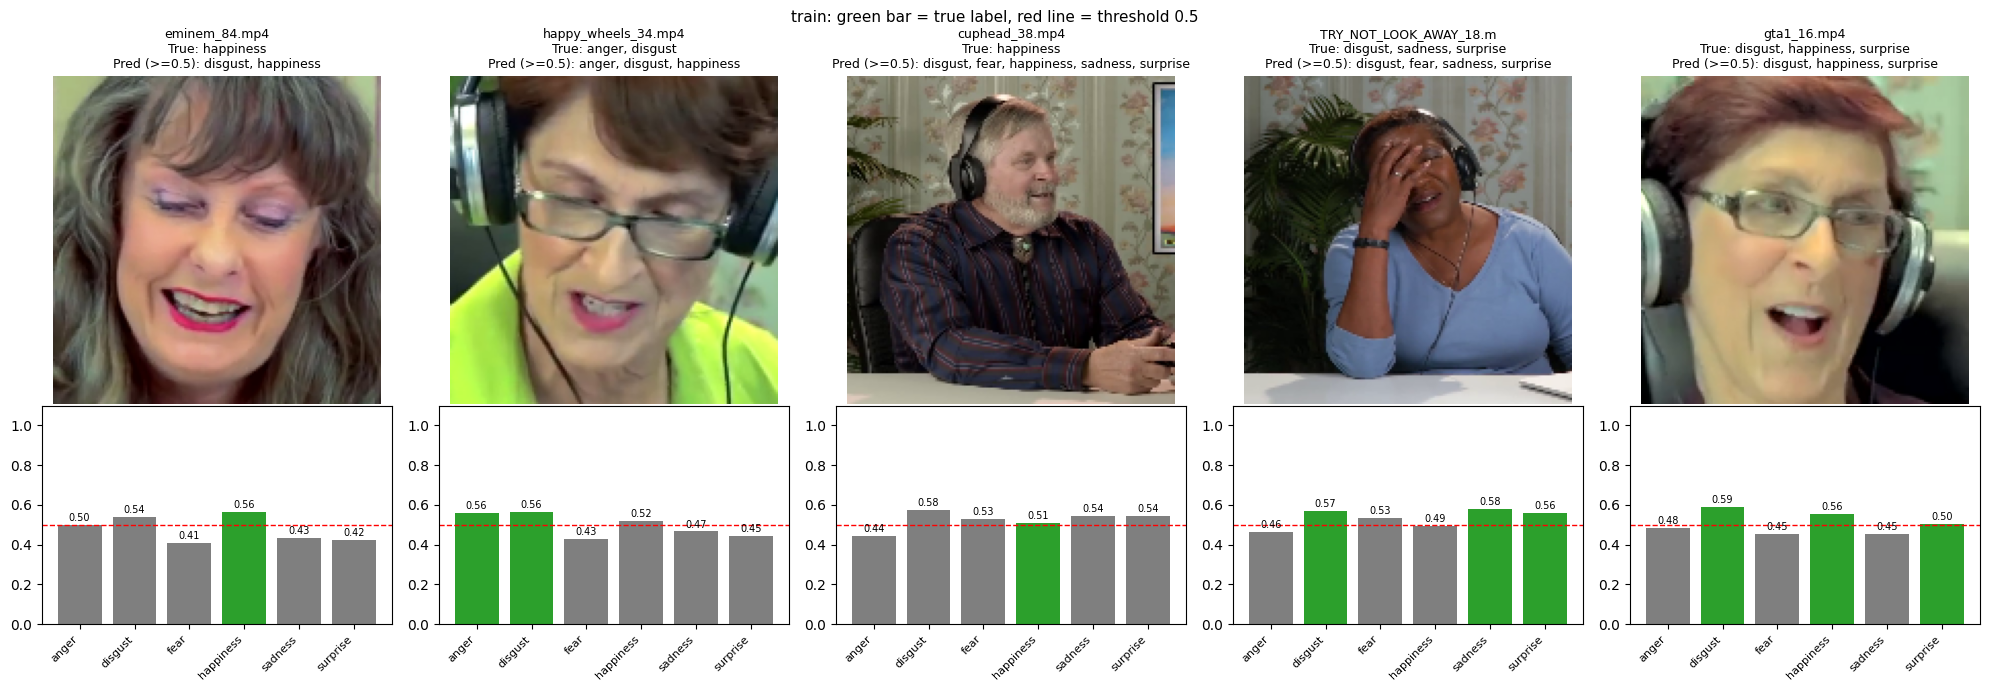

saved /content/elderreact_ckpt/predictions_train.csv

================ VAL (2 clips) ================
loss 0.7437 | mean F1@0.5 0.167 | mAP 1.000
per-class F1@0.5: {'anger': 0.0, 'disgust': 0.0, 'fear': 0.0, 'happiness': 1.0, 'sadness': 0.0, 'surprise': 0.0}

--- val: sigmoid probability per emotion (independent, do NOT sum to 1) ---
video                            anger   disgust      fear happiness   sadness  surprise   true labels
godofwar_87.mp4                  0.456     0.572     0.518     0.503     0.547     0.551   happiness
eminem_144.mp4                   0.492     0.577     0.496     0.502     0.544     0.532   happiness

--- val: decision rules (how many emotions to output) ---
rule                        microF1  macroF1  sampleF1  avg #pred
thr>=0.3                      0.286    0.167     0.286       6.00
thr>=0.5                      0.364    0.167     0.367       4.50
thr>=0.7                      0.000    0.000     0.000       0.00
thr>=0.8                      0.000 

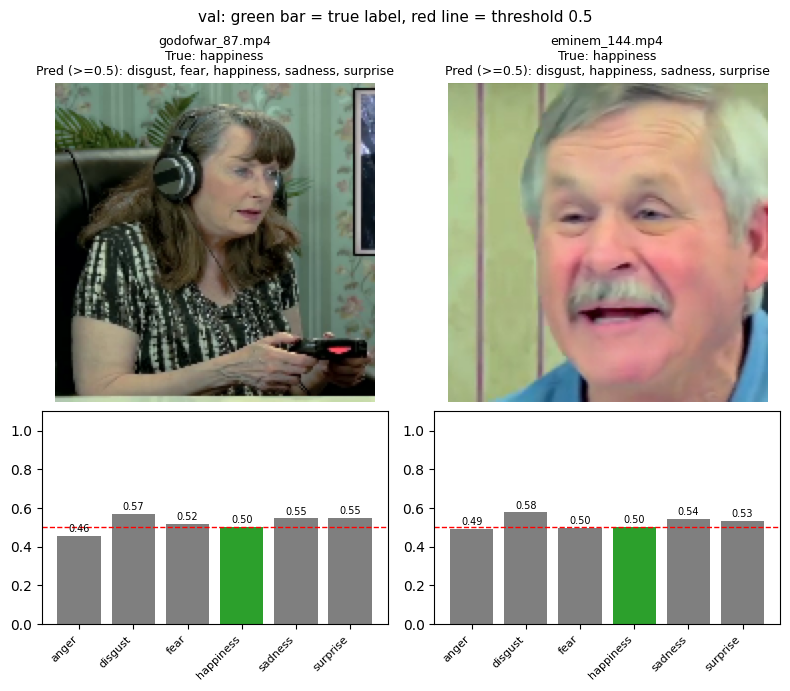

saved /content/elderreact_ckpt/predictions_val.csv

================ TEST (10 clips) ================
loss 0.7778 | mean F1@0.5 0.295 | mAP 0.556
per-class F1@0.5: {'anger': 0.4, 'disgust': 0.333, 'fear': 0.0, 'happiness': 0.75, 'sadness': 0.0, 'surprise': 0.286}

--- test: sigmoid probability per emotion (independent, do NOT sum to 1) ---
video                            anger   disgust      fear happiness   sadness  surprise   true labels
game_of_thrones_65.mp4           0.491     0.568     0.455     0.528     0.477     0.474   anger, disgust
pewdiepie_38.mp4                 0.499     0.569     0.439     0.535     0.461     0.454   happiness, surprise
qwop_35.mp4                      0.553     0.552     0.484     0.497     0.519     0.495   happiness, surprise
david_bowie_23.mp4               0.481     0.570     0.464     0.524     0.464     0.474   happiness, surprise
dolan_dark_88.mp4                0.496     0.558     0.443     0.540     0.476     0.460   happiness, surprise
marsh

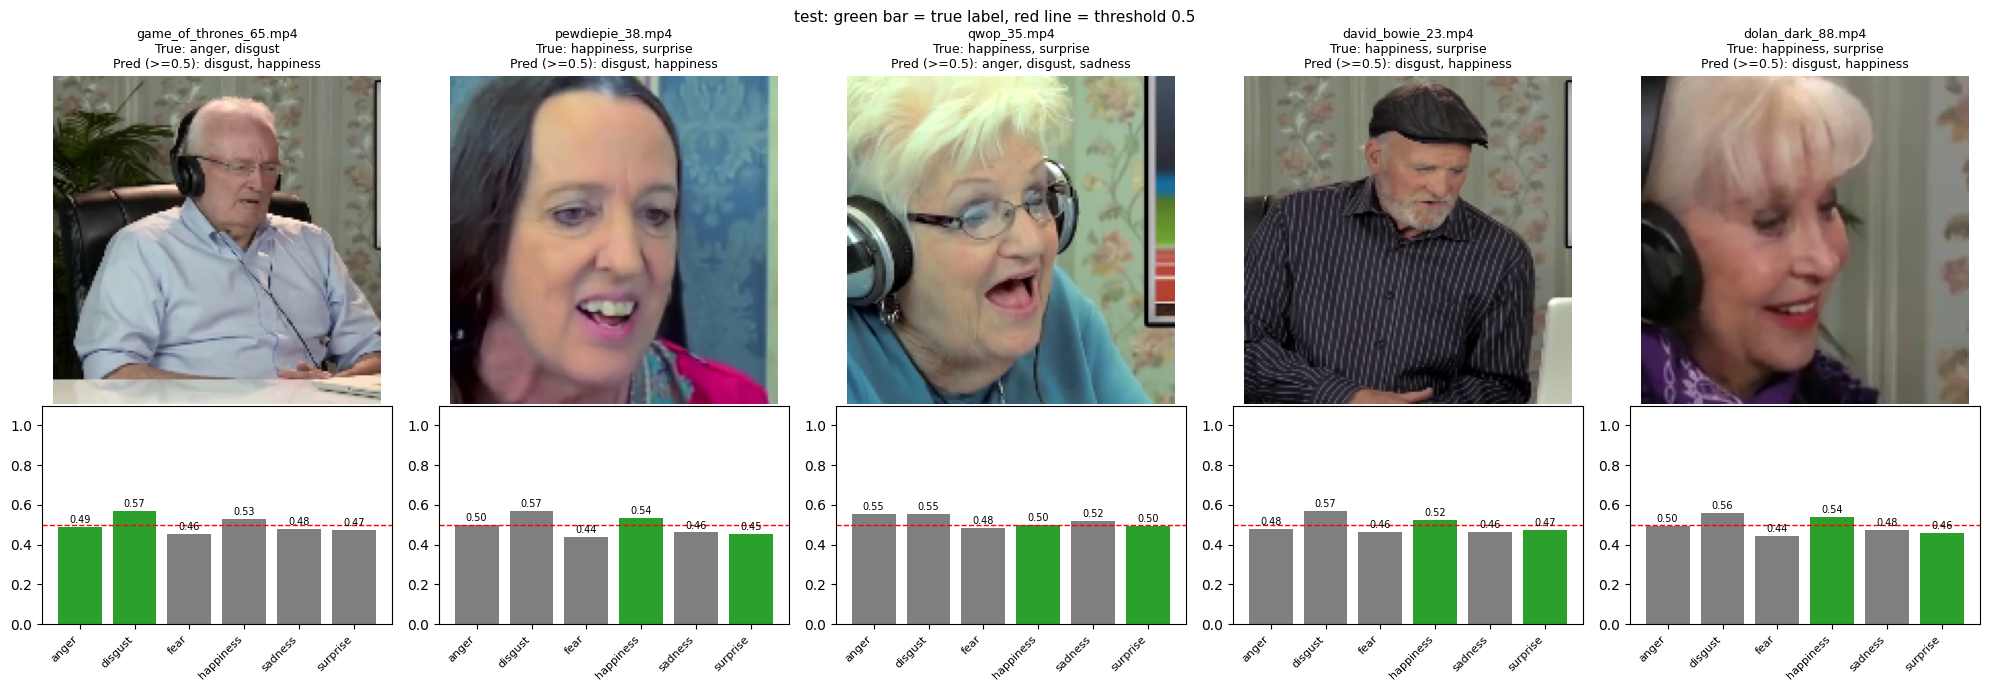

saved /content/elderreact_ckpt/predictions_test.csv


In [2]:
# Fine-tune MAE-DFER on ElderReact (multi-label, 6 emotions)
# v2: periodic best-checkpoint saving, test-set evaluation, plots, per-emotion probabilities
#
# Run in a Colab cell (so plots show inline), after:
#   from google.colab import drive; drive.mount('/content/drive')
#   !git clone https://github.com/sunlicai/MAE-DFER.git /content/MAE-DFER   (once)

import os, sys, random, time, glob, csv, shutil
import numpy as np
import cv2
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from decord import VideoReader, cpu
from sklearn.metrics import f1_score, average_precision_score

# OpenCV's OpenCL path crashes inside forked DataLoader workers on Colab (CL_MEM_OBJECT_ALLOCATION_FAILURE)
cv2.ocl.setUseOpenCL(False)
cv2.setNumThreads(0)

# ============================ CONFIG ============================
REPO_DIR   = '/content/MAE-DFER'
CKPT       = '/content/drive/MyDrive/plugg/year5/projektkurs/checkpoints/checkpoint-49.pth'  # <-- use the path that worked for you
BASE       = '/content/drive/MyDrive/plugg/year5/projektkurs'
DATA_DIR   = f'{BASE}/ElderReact_Data'                       # train videos
LABEL_FILE = f'{BASE}/ElderReact_Data/train_labels.txt'
TEST_DIR   = f'{BASE}/ElderReact_Data/ElderReact_test'       # <-- adjust if the test folder lives elsewhere
TEST_LABEL_FILE = f'{BASE}/ElderReact_Data/test_labels.txt'

SAVE_DIR       = '/content/elderreact_ckpt'   # Colab-local (wiped if the runtime disconnects)
COPY_TO_DRIVE  = False                        # also copy checkpoint/CSVs/plots to Drive?
DRIVE_COPY_DIR = f'{BASE}/elderreact_ft'
SAVE_EVERY     = 5                            # check every N epochs; only writes if val score improved since last write
SELECT_METRIC  = 'mean_f1'                    # 'mean_f1' or 'mAP' (mAP is steadier when val is tiny)
EVAL_ONLY_CKPT = None                         # e.g. '/content/elderreact_ckpt/best.pth' to skip training and just evaluate

# The authors' DFEW script uses this name; the LGI-Former structure is switched on by the kwargs below
# (--depth 16 --attn_type local_global --lg_region_size 2 5 10), not by the name.
MODEL_NAME = 'vit_base_dim512_no_depth_patch16_160'
DEPTH = 16
ATTN_TYPE = 'local_global'
LG_REGION_SIZE = [2, 5, 10]
LG_CLASSIFY_TOKEN_TYPE = 'region'   # <-- CHECK: value of lg_classify_token_type in the DFEW finetune .sh (top of file)
EMOTIONS   = ['anger', 'disgust', 'fear', 'happiness', 'sadness', 'surprise']   # must match txt column order
NUM_FRAMES, TUBELET, SIZE = 16, 2, 160

EPOCHS, BATCH_SIZE = 30, 8
LR_BACKBONE, LR_HEAD, WEIGHT_DECAY = 5e-5, 5e-4, 0.05
WARMUP_EPOCHS = 3
VAL_FRACTION, SEED = 0.2, 42
MAX_VIDEOS = 10          # None = use all training videos
MAX_TEST_VIDEOS = 10     # None = use all test videos
USE_FACE_CROP = True
NUM_WORKERS = 2

N_PLOT = 5               # videos to plot for train and test
PLOT_THRESHOLD = 0.5     # threshold used only for the "Pred" text in the plots
# =================================================================

sys.path.append(REPO_DIR)
import modeling_finetune  # noqa: F401
from timm.models import create_model, list_models

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
os.makedirs(SAVE_DIR, exist_ok=True)

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
VIDEO_EXTS = ['', '.mp4', '.avi', '.mov', '.mkv', '.webm']


def maybe_copy_to_drive(path):
    if COPY_TO_DRIVE:
        os.makedirs(DRIVE_COPY_DIR, exist_ok=True)
        shutil.copy(path, DRIVE_COPY_DIR)


# ------------------------- labels / data -------------------------
def find_video(name, data_dir):
    for ext in VIDEO_EXTS:
        p = os.path.join(data_dir, name + ext)
        if os.path.isfile(p):
            return p
    hits = glob.glob(os.path.join(data_dir, '**', os.path.splitext(name)[0] + '.*'), recursive=True)
    return hits[0] if hits else None


def read_labels(label_path, data_dir):
    items, missing = [], 0
    with open(label_path) as f:
        for line in f:
            parts = line.replace(',', ' ').split()
            if len(parts) < 7:
                continue
            try:
                y = [float(v) for v in parts[1:7]]
            except ValueError:      # header line
                continue
            vp = find_video(parts[0], data_dir)
            if vp is None:
                missing += 1
                continue
            items.append((vp, y))
    print(f'{os.path.basename(label_path)}: found {len(items)} labelled videos ({missing} listed but not on disk) in {data_dir}')
    return items


def label_stats(name, items):
    Y = np.array([y for _, y in items])
    print(f'{name}: {len(Y)} clips | avg labels/clip {Y.sum(1).mean():.2f} | '
          f'0 labels: {(Y.sum(1) == 0).sum()} | 1 label: {(Y.sum(1) == 1).sum()} | 2+ labels: {(Y.sum(1) >= 2).sum()}')


_face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def face_box(frame, margin=0.3):
    gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
    try:
        faces = _face_cascade.detectMultiScale(gray, 1.1, 5, minSize=(40, 40))
    except cv2.error:
        return None
    if len(faces) == 0:
        return None
    x, y, w, h = max(faces, key=lambda b: b[2] * b[3])
    H, W = frame.shape[:2]
    s = int(max(w, h) * (1 + margin)); cx, cy = x + w // 2, y + h // 2
    x0, y0 = max(0, cx - s // 2), max(0, cy - s // 2)
    return x0, y0, min(W, x0 + s), min(H, y0 + s)


class ElderReactDataset(Dataset):
    def __init__(self, items, train):
        self.items, self.train = items, train

    def __len__(self):
        return len(self.items)

    def _indices(self, n):
        seg = np.linspace(0, n, NUM_FRAMES + 1)
        if self.train:
            idx = [random.randint(int(seg[i]), max(int(seg[i]), int(seg[i + 1]) - 1)) for i in range(NUM_FRAMES)]
        else:
            idx = [int((seg[i] + seg[i + 1]) / 2) for i in range(NUM_FRAMES)]
        return np.clip(idx, 0, n - 1)

    def __getitem__(self, i):
        path, y = self.items[i]
        try:
            vr = VideoReader(path, ctx=cpu(0))
            frames = vr.get_batch(self._indices(len(vr))).asnumpy()
        except Exception as e:
            print('bad video', path, e)
            frames = np.zeros((NUM_FRAMES, SIZE, SIZE, 3), dtype=np.uint8)

        if USE_FACE_CROP:
            box = face_box(frames[len(frames) // 2])
            if box:
                x0, y0, x1, y1 = box
                frames = frames[:, y0:y1, x0:x1]

        flip = self.train and random.random() < 0.5
        out = []
        for f in frames:
            f = cv2.resize(f, (SIZE, SIZE))
            if flip:
                f = f[:, ::-1]
            out.append((f.astype(np.float32) / 255.0 - MEAN) / STD)
        x = torch.from_numpy(np.stack(out).transpose(3, 0, 1, 2).copy())
        return x, torch.tensor(y, dtype=torch.float32)

    def preview(self, i):
        """Middle frame (face-cropped like the model input) for plotting."""
        path, _ = self.items[i]
        try:
            vr = VideoReader(path, ctx=cpu(0))
            fr = vr.get_batch([len(vr) // 2]).asnumpy()[0]
            if USE_FACE_CROP:
                box = face_box(fr)
                if box:
                    x0, y0, x1, y1 = box
                    fr = fr[y0:y1, x0:x1]
            return cv2.resize(fr, (SIZE, SIZE))
        except Exception:
            return np.zeros((SIZE, SIZE, 3), dtype=np.uint8)


def make_loader(items, train=False):
    return DataLoader(ElderReactDataset(items, train), batch_size=BATCH_SIZE, shuffle=train,
                      num_workers=NUM_WORKERS, drop_last=train and len(items) > BATCH_SIZE, pin_memory=True)


# ------------------------- model -------------------------
def build_model():
    print('registered dim512 models:', list_models('*dim512*'))
    model = create_model(MODEL_NAME, pretrained=False, num_classes=len(EMOTIONS),
                         all_frames=NUM_FRAMES, tubelet_size=TUBELET, drop_path_rate=0.1,
                         depth=DEPTH, attn_type=ATTN_TYPE, lg_region_size=LG_REGION_SIZE,
                         lg_classify_token_type=LG_CLASSIFY_TOKEN_TYPE)
    ckpt = torch.load(CKPT, map_location='cpu', weights_only=False)
    sd = next((ckpt[k] for k in ('model', 'module', 'state_dict') if k in ckpt), ckpt)
    sd = {(k[len('encoder.'):] if k.startswith('encoder.') else k): v for k, v in sd.items()}
    sd = {k: v for k, v in sd.items() if not k.startswith('decoder') and not k.startswith('head')}
    msg = model.load_state_dict(sd, strict=False)
    print(f'missing keys: {len(msg.missing_keys)} (first 5: {msg.missing_keys[:5]})')
    print(f'unexpected keys: {len(msg.unexpected_keys)} (first 5: {msg.unexpected_keys[:5]})')
    # Only the new classification head (and fc_norm) may be missing. Anything else = architecture mismatch.
    bad = [k for k in msg.missing_keys if not (k.startswith('head') or k.startswith('fc_norm'))]
    if bad:
        raise RuntimeError(f'{len(bad)} encoder weights were NOT loaded (e.g. {bad[:3]}). '
                           f'MODEL_NAME={MODEL_NAME} does not match the checkpoint architecture. '
                           f'Pick one of: {list_models("*dim512*")}')
    # Checkpoint encoder weights that found no home are also a mismatch (leftovers like mask_token/norm are fine).
    unused = [k for k in msg.unexpected_keys if k.startswith(('blocks.', 'patch_embed', 'lg_'))]
    if unused:
        raise RuntimeError(f'{len(unused)} checkpoint encoder weights were NOT used (e.g. {unused[:3]}). '
                           f'Model kwargs (DEPTH / ATTN_TYPE / LG_*) do not match the pre-trained encoder.')
    print('OK: all encoder weights loaded; only the new head is randomly initialised.')
    return model


def save_ckpt(state, score, epoch):
    path = os.path.join(SAVE_DIR, 'best.pth')
    torch.save({'model': state, 'epoch': epoch, 'score': float(score), 'metric': SELECT_METRIC}, path)
    print(f'   >> saved best.pth (epoch {epoch}, {SELECT_METRIC}={score:.3f}) -> {SAVE_DIR}')
    maybe_copy_to_drive(path)


# ------------------------- evaluation -------------------------
@torch.no_grad()
def evaluate(model, items, criterion=None):
    """Returns dict with probs (sigmoid, per emotion), labels, loss, F1s, mAP."""
    model.eval()
    logits = []
    for x, _ in make_loader(items):
        with torch.autocast(device_type='cuda', enabled=device == 'cuda'):
            out = model(x.to(device))
        logits.append(out.float().cpu())
    logits = torch.cat(logits)
    y = np.array([lab for _, lab in items], dtype=np.float32)
    loss = criterion(logits.to(device), torch.tensor(y).to(device)).item() if criterion is not None else float('nan')
    probs = torch.sigmoid(logits).numpy()
    pred = (probs > 0.5).astype(int)
    f1s = [f1_score(y[:, c], pred[:, c], zero_division=0) for c in range(y.shape[1])]
    aps = [average_precision_score(y[:, c], probs[:, c]) if y[:, c].sum() > 0 else np.nan for c in range(y.shape[1])]
    return dict(probs=probs, y=y, loss=loss, f1=f1s, mean_f1=float(np.mean(f1s)),
                mAP=float(np.nan_to_num(np.nanmean(aps)) if not np.all(np.isnan(aps)) else 0.0))


def decide(probs, thr=0.5, max_k=None, min_k=0):
    """Turn per-emotion probabilities into 0/1 predictions.
    thr: keep emotions with prob >= thr | max_k: keep at most k highest | min_k: force at least k highest."""
    pred = probs >= thr
    rank = np.argsort(np.argsort(-probs, axis=1), axis=1)   # 0 = highest prob
    if max_k is not None:
        pred &= rank < max_k
    if min_k:
        pred |= rank < min_k
    return pred.astype(int)


RULES = [
    ('thr>=0.3',                 dict(thr=0.3)),
    ('thr>=0.5',                 dict(thr=0.5)),
    ('thr>=0.7',                 dict(thr=0.7)),
    ('thr>=0.8',                 dict(thr=0.8)),
    ('top-1 only',               dict(thr=0.0, max_k=1)),
    ('top-2 only',               dict(thr=0.0, max_k=2)),
    ('thr>=0.5, at least 1',     dict(thr=0.5, min_k=1)),
    ('thr>=0.5, 1-2 emotions',   dict(thr=0.5, min_k=1, max_k=2)),
    ('thr>=0.8, at least 1',     dict(thr=0.8, min_k=1)),
]

def rules_table(split, probs, y):
    print(f'\n--- {split}: decision rules (how many emotions to output) ---')
    print(f'{"rule":<26}{"microF1":>9}{"macroF1":>9}{"sampleF1":>10}{"avg #pred":>11}')
    for name, kw in RULES:
        pred = decide(probs, **kw)
        print(f'{name:<26}'
              f'{f1_score(y, pred, average="micro", zero_division=0):>9.3f}'
              f'{f1_score(y, pred, average="macro", zero_division=0):>9.3f}'
              f'{f1_score(y, pred, average="samples", zero_division=0):>10.3f}'
              f'{pred.sum(1).mean():>11.2f}')
    print(f'(true avg #labels per clip: {y.sum(1).mean():.2f})')


def print_prob_table(split, items, probs):
    print(f'\n--- {split}: sigmoid probability per emotion (independent, do NOT sum to 1) ---')
    print(f'{"video":<28}' + ''.join(f'{e[:9]:>10}' for e in EMOTIONS) + '   true labels')
    for (p, y), pr in zip(items, probs):
        true = ', '.join(e for e, v in zip(EMOTIONS, y) if v > 0.5) or '-'
        print(f'{os.path.basename(p)[:27]:<28}' + ''.join(f'{v:>10.3f}' for v in pr) + f'   {true}')


def plot_predictions(split, items, probs, n=N_PLOT, thr=PLOT_THRESHOLD):
    n = min(n, len(items))
    ds = ElderReactDataset(items, False)
    fig, axes = plt.subplots(2, n, figsize=(4 * n, 7), gridspec_kw={'height_ratios': [3, 2]}, squeeze=False)
    for j in range(n):
        path, y = items[j]
        true = [e for e, v in zip(EMOTIONS, y) if v > 0.5] or ['none']
        pred = [e for e, p in zip(EMOTIONS, probs[j]) if p >= thr] or ['none']
        axes[0, j].imshow(ds.preview(j)); axes[0, j].axis('off')
        axes[0, j].set_title(f'{os.path.basename(path)[:22]}\nTrue: {", ".join(true)}\nPred (>={thr}): {", ".join(pred)}', fontsize=9)
        colors = ['tab:green' if v > 0.5 else 'tab:gray' for v in y]
        axes[1, j].bar(range(len(EMOTIONS)), probs[j], color=colors)
        axes[1, j].axhline(thr, ls='--', c='red', lw=1)
        axes[1, j].set_ylim(0, 1.1)
        axes[1, j].set_xticks(range(len(EMOTIONS)))
        axes[1, j].set_xticklabels(EMOTIONS, rotation=45, ha='right', fontsize=8)
        for k, p in enumerate(probs[j]):
            axes[1, j].text(k, min(p + 0.02, 1.0), f'{p:.2f}', ha='center', fontsize=7)
    fig.suptitle(f'{split}: green bar = true label, red line = threshold {thr}', fontsize=11)
    plt.tight_layout()
    path = os.path.join(SAVE_DIR, f'plot_{split}.png')
    fig.savefig(path, dpi=120)
    maybe_copy_to_drive(path)
    plt.show()


def save_csv(split, items, probs):
    path = os.path.join(SAVE_DIR, f'predictions_{split}.csv')
    with open(path, 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['video'] + [f'true_{e}' for e in EMOTIONS] + [f'prob_{e}' for e in EMOTIONS])
        for (p, y), pr in zip(items, probs):
            w.writerow([os.path.basename(p)] + [int(v) for v in y] + [f'{v:.4f}' for v in pr])
    print(f'saved {path}')
    maybe_copy_to_drive(path)


def report(model, split, items, criterion, with_metrics=True):
    res = evaluate(model, items, criterion)
    print(f'\n================ {split.upper()} ({len(items)} clips) ================')
    if with_metrics:
        print(f'loss {res["loss"]:.4f} | mean F1@0.5 {res["mean_f1"]:.3f} | mAP {res["mAP"]:.3f}')
        print('per-class F1@0.5:', {e: round(f, 3) for e, f in zip(EMOTIONS, res['f1'])})
    print_prob_table(split, items, res['probs'])
    if with_metrics:
        rules_table(split, res['probs'], res['y'])
    plot_predictions(split, items, res['probs'])
    save_csv(split, items, res['probs'])
    return res


# ------------------------- main -------------------------
def main():
    items = read_labels(LABEL_FILE, DATA_DIR)
    if not items:
        raise SystemExit('No training videos found - check DATA_DIR / LABEL_FILE.')
    test_items = read_labels(TEST_LABEL_FILE, TEST_DIR)
    if not test_items:
        raise SystemExit('No test videos found - check TEST_DIR / TEST_LABEL_FILE.')

    random.shuffle(items)
    if MAX_VIDEOS:
        items = items[:MAX_VIDEOS]
    rng = random.Random(SEED); rng.shuffle(test_items)
    if MAX_TEST_VIDEOS:
        test_items = test_items[:MAX_TEST_VIDEOS]

    n_val = max(1, int(len(items) * VAL_FRACTION))
    val_items, train_items = items[:n_val], items[n_val:]
    print(f'train {len(train_items)} | val {len(val_items)} | test {len(test_items)}')
    label_stats('train', train_items); label_stats('test ', test_items)

    Y = np.array([y for _, y in train_items])
    pos = Y.sum(0); neg = len(Y) - pos
    pos_weight = torch.tensor(np.clip(neg / np.maximum(pos, 1), 1, 10), dtype=torch.float32).to(device)
    print('positives per class:', dict(zip(EMOTIONS, pos.astype(int))), '| pos_weight:', pos_weight.cpu().numpy().round(2))
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    model = build_model().to(device)

    if EVAL_ONLY_CKPT:
        model.load_state_dict(torch.load(EVAL_ONLY_CKPT, map_location='cpu')['model'])
        print('loaded', EVAL_ONLY_CKPT, '- skipping training')
    else:
        tr = make_loader(train_items, train=True)
        head_params = [p for n, p in model.named_parameters() if n.startswith('head') or n.startswith('fc_norm')]
        head_ids = {id(p) for p in head_params}
        backbone = [p for p in model.parameters() if id(p) not in head_ids]
        optimizer = torch.optim.AdamW([{'params': backbone, 'lr': LR_BACKBONE},
                                       {'params': head_params, 'lr': LR_HEAD}], weight_decay=WEIGHT_DECAY)
        base_lrs = [LR_BACKBONE, LR_HEAD]
        total_steps, warm_steps = EPOCHS * len(tr), max(1, WARMUP_EPOCHS * len(tr))
        scaler = torch.cuda.amp.GradScaler(enabled=device == 'cuda')

        best, best_epoch, best_state, last_saved, step = -1.0, 0, None, -1.0, 0
        try:
            for epoch in range(EPOCHS):
                model.train(); t0 = time.time(); run = 0.0
                for x, y in tr:
                    scale = (step + 1) / warm_steps if step < warm_steps else \
                        0.5 * (1 + np.cos(np.pi * (step - warm_steps) / max(1, total_steps - warm_steps)))
                    for g, b in zip(optimizer.param_groups, base_lrs):
                        g['lr'] = b * scale
                    x, y = x.to(device), y.to(device)
                    with torch.autocast(device_type='cuda', enabled=device == 'cuda'):
                        logits = model(x)
                    loss = criterion(logits.float(), y)
                    optimizer.zero_grad(set_to_none=True)
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer); scaler.update()
                    run += loss.item(); step += 1

                m = evaluate(model, val_items, criterion)
                score = m[SELECT_METRIC]
                print(f'epoch {epoch+1:02d}/{EPOCHS} | train loss {run/len(tr):.4f} | val loss {m["loss"]:.4f} '
                      f'| mean F1 {m["mean_f1"]:.3f} | mAP {m["mAP"]:.3f} | {time.time()-t0:.0f}s')
                print('   per-class F1:', {e: round(f, 3) for e, f in zip(EMOTIONS, m['f1'])})

                if score > best:     # keep best weights in memory
                    best, best_epoch = score, epoch + 1
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                    print(f'   new best {SELECT_METRIC}={best:.3f}')

                # every SAVE_EVERY epochs: write to disk, but only if the best score improved since the last write
                if (epoch + 1) % SAVE_EVERY == 0 and best_state is not None and best > last_saved:
                    save_ckpt(best_state, best, best_epoch); last_saved = best
        except KeyboardInterrupt:
            print('\nTraining interrupted - saving best weights so far.')

        if best_state is not None:
            if best > last_saved:
                save_ckpt(best_state, best, best_epoch)
            model.load_state_dict(best_state)
            print(f'using best weights from epoch {best_epoch} ({SELECT_METRIC}={best:.3f})')

    # ---- final reports: train subset (plots only), val, test ----
    report(model, 'train', train_items[:N_PLOT], criterion, with_metrics=False)
    report(model, 'val', val_items, criterion)
    report(model, 'test', test_items, criterion)


if __name__ == '__main__':
    main()

In [12]:
!sed -n 1,24p /content/MAE-DFER/scripts/dfew/finetune_local_global_attn_depth16_region_size2510_with_diff_target_164.sh
!grep -n "lg_\|use_mean_pooling\|init_scale\|--depth\|attn_type" /content/MAE-DFER/run_class_finetuning.py | head -40

server=164
pretrain_dataset='voxceleb2'
pretrain_server=170
finetune_dataset='dfew'
num_labels=7
ckpts=(49)
input_size=160
sr=4
model="videomae_pretrain_base_dim512_local_global_attn_depth16_region_size2510_patch16_160_frame_16x4_tube_mask_ratio_0.9_e100_with_diff_target"
model_dir="${model}_server${pretrain_server}"

splits=(1) # you can change it to other folds, e.g., (2,3,4,5)
lr=1e-3
epochs=100
lg_classify_token_types=('region')
for ckpt in "${ckpts[@]}";
do
  for split in "${splits[@]}";
  do
    for lg_classify_token_type in "${lg_classify_token_types[@]}";
    do
      OUTPUT_DIR="./saved/model/finetuning/${finetune_dataset}/${pretrain_dataset}_${model_dir}/checkpoint-${ckpt}/eval_split0${split}_lr_${lr}_epoch_${epochs}_size${input_size}_sr${sr}_classify_token_type_${lg_classify_token_type}_server${server}"
      if [ ! -d "$OUTPUT_DIR" ]; then
        mkdir -p $OUTPUT_DIR
53:    parser.add_argument('--attn_type', default='local_global',
55:    parser.add_argument('--lg_region_s